
**Course Code:** ECOM 6339 / 6176

**Instructor:** Dr. Khalil Abu Zanouneh

**Academic Year:** 2026–2027

**Student:** Dalya Awad Mohammad Hassan

**Student ID:** 220253121

**University:** Islamic University of Gaza

**Submission:** Assignment 01 — Supporting Python Code


**Assignment Overview**

This notebook contains the Python implementation and numerical analysis for Assignment 01: Performance Analysis and Scaling Laws.

The objective is to evaluate parallel computing performance using theoretical scaling laws, experimental execution times, and statistical analysis.

**Tools and Libraries**

Python 3

NumPy — Numerical calculations

Matplotlib — Data visualization

Pandas — Tabular data analysis

Google Colab — Execution environment

**Reproducibility**

All calculations are based on the formulas, measured execution times, and datasets provided in the assignment and course lecture materials. Each task is organized into separate sections containing its corresponding Python code and generated results.

The complete mathematical derivations, interpretations, and discussions are provided in the accompanying PDF report.

**Task 1 Amdahl's Law - Question 3**

Processors (p) | Speedup S(p)
-------------------------------
             1 | 1.0000
             2 | 1.9048
             4 | 3.4783
             8 | 5.9259
            16 | 9.1429
            64 | 15.4217
          1024 | 19.6357


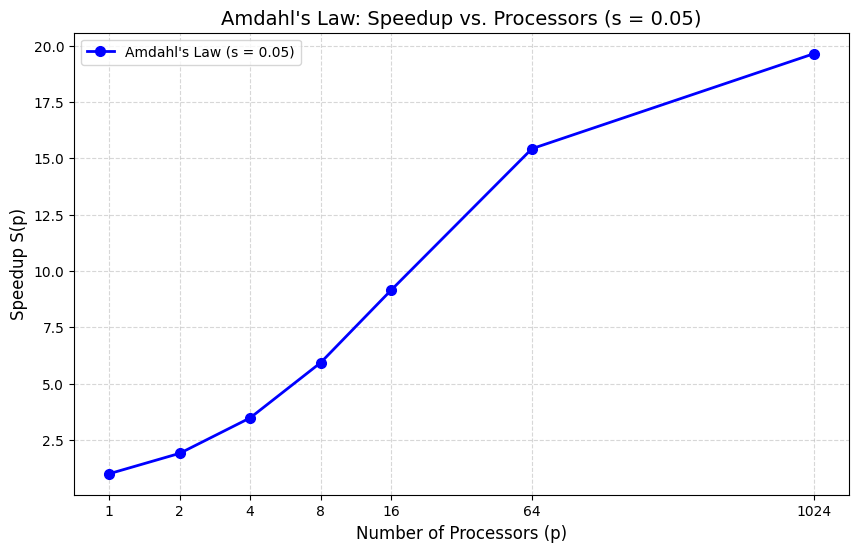

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Task 1 - Question 3: Amdahl's Law
# Serial fraction = 5%
s = 0.05

# Required processor counts
processors = np.array([1, 2, 4, 8, 16, 64, 1024])

# Amdahl's Law
def amdahl_speedup(p, s):
    return 1 / (s + (1 - s) / p)

# Calculate speedup
speedup = amdahl_speedup(processors, s)

# Print calculated results
print("Processors (p) | Speedup S(p)")
print("-" * 31)

for p, sp in zip(processors, speedup):
    print(f"{p:14d} | {sp:.4f}")

# Create figure
plt.figure(figsize=(10, 6))

# Plot speedup
plt.plot(
    processors,
    speedup,
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=7,
    color='blue',
    label="Amdahl's Law (s = 0.05)"
)

# Logarithmic scale for processor count
plt.xscale('log', base=2)

# Display exact processor counts
plt.xticks(processors, labels=[str(p) for p in processors])

# Chart labels
plt.xlabel("Number of Processors (p)", fontsize=12)
plt.ylabel("Speedup S(p)", fontsize=12)
plt.title("Amdahl's Law: Speedup vs. Processors (s = 0.05)",
          fontsize=14)

# Add grid and legend
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

# Save result as image
plt.savefig("amdahl_task1_q3.png", dpi=300, bbox_inches='tight')

# Display graph
plt.show()


In [ ]:
from google.colab import files

files.download("amdahl_task1_q3.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 1 Amdahl's Law - Question 4**


Serial Fraction: s = 0.05
Processors (p) | Speedup S(p)
-------------------------------
             1 | 1.0000
             2 | 1.9048
             4 | 3.4783
             8 | 5.9259
            16 | 9.1429
            64 | 15.4217
          1024 | 19.6357

Serial Fraction: s = 0.10
Processors (p) | Speedup S(p)
-------------------------------
             1 | 1.0000
             2 | 1.8182
             4 | 3.0769
             8 | 4.7059
            16 | 6.4000
            64 | 8.7671
          1024 | 9.9129

Serial Fraction: s = 0.20
Processors (p) | Speedup S(p)
-------------------------------
             1 | 1.0000
             2 | 1.6667
             4 | 2.5000
             8 | 3.3333
            16 | 4.0000
            64 | 4.7059
          1024 | 4.9805


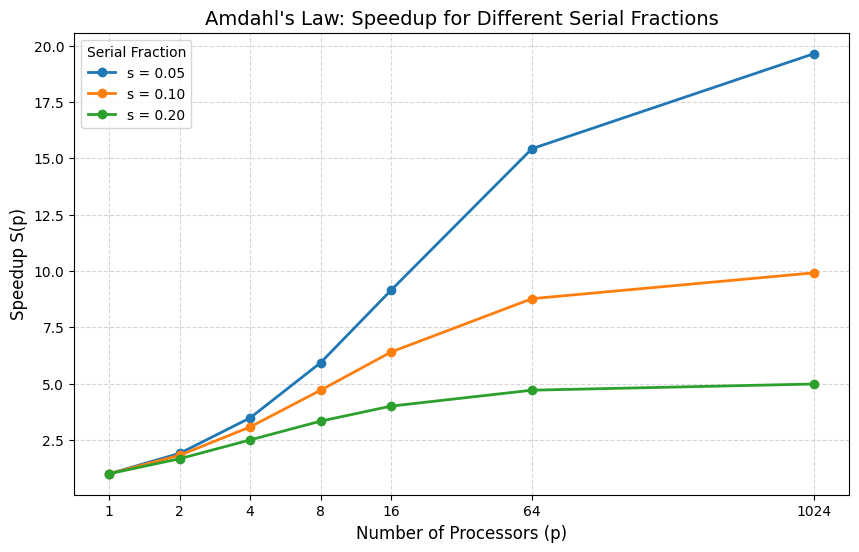

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Assignment 1 - Task 1 - Question 4
# Amdahl's Law: Comparison of three serial fractions

# Required processor counts
processors = np.array([1, 2, 4, 8, 16, 64, 1024])

# Serial fractions
serial_fractions = [0.05, 0.10, 0.20]

# Amdahl's Law
def amdahl_speedup(p, s):
    return 1 / (s + (1 - s) / p)

# Create figure
plt.figure(figsize=(10, 6))

# Plot all three serial fractions
for s in serial_fractions:

    speedup = amdahl_speedup(processors, s)

    # Print results
    print(f"\nSerial Fraction: s = {s:.2f}")
    print("Processors (p) | Speedup S(p)")
    print("-" * 31)

    for p, sp in zip(processors, speedup):
        print(f"{p:14d} | {sp:.4f}")

    # Plot current serial fraction
    plt.plot(
        processors,
        speedup,
        marker='o',
        linestyle='-',
        linewidth=2,
        markersize=6,
        label=f"s = {s:.2f}"
    )

# Logarithmic scale for x-axis
plt.xscale('log', base=2)

# Show exact processor counts
plt.xticks(
    processors,
    labels=[str(p) for p in processors]
)

# Axis labels and title
plt.xlabel("Number of Processors (p)", fontsize=12)
plt.ylabel("Speedup S(p)", fontsize=12)
plt.title(
    "Amdahl's Law: Speedup for Different Serial Fractions",
    fontsize=14
)

# Grid and legend
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(title="Serial Fraction")

# Save graph
plt.savefig(
    "amdahl_task1_q4.png",
    dpi=300,
    bbox_inches='tight'
)

# Display graph
plt.show()


In [ ]:
from google.colab import files

files.download("amdahl_task1_q4.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 2 Gustafson’s Law - Question 7**

Processors | Amdahl Speedup | Gustafson Speedup
-------------------------------------------------
         1 |         1.0000 |            1.0000
         2 |         1.9048 |            1.9500
         4 |         3.4783 |            3.8500
         8 |         5.9259 |            7.6500
        16 |         9.1429 |           15.2500
        64 |        15.4217 |           60.8500
      1024 |        19.6357 |          972.8500


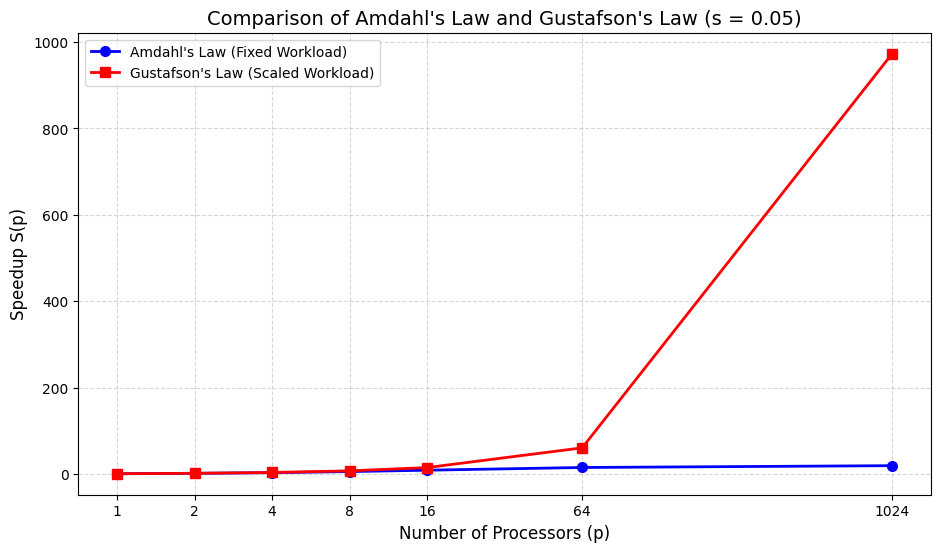

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Assignment 1 - Task 2 - Question 7
# Comparison: Amdahl's Law vs. Gustafson's Law

# Given serial fraction
s = 0.05

# Required processor counts
processors = np.array([1, 2, 4, 8, 16, 64, 1024])

# Amdahl's Law
def amdahl_speedup(p, s):
    return 1 / (s + (1 - s) / p)

# Gustafson's Law
def gustafson_speedup(p, s):
    return s + p * (1 - s)

# Calculate speedups
amdahl = amdahl_speedup(processors, s)
gustafson = gustafson_speedup(processors, s)

# Print results
print("Processors | Amdahl Speedup | Gustafson Speedup")
print("-" * 49)

for p, a, g in zip(processors, amdahl, gustafson):
    print(f"{p:10d} | {a:14.4f} | {g:17.4f}")

# Create comparison graph
plt.figure(figsize=(11, 6))

# Plot Amdahl's Law
plt.plot(
    processors,
    amdahl,
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=7,
    color='blue',
    label="Amdahl's Law (Fixed Workload)"
)

# Plot Gustafson's Law
plt.plot(
    processors,
    gustafson,
    marker='s',
    linestyle='-',
    linewidth=2,
    markersize=7,
    color='red',
    label="Gustafson's Law (Scaled Workload)"
)

# Logarithmic processor axis
plt.xscale('log', base=2)
plt.xticks(processors, [str(p) for p in processors])

# Labels and title
plt.xlabel("Number of Processors (p)", fontsize=12)
plt.ylabel("Speedup S(p)", fontsize=12)
plt.title(
    "Comparison of Amdahl's Law and Gustafson's Law (s = 0.05)",
    fontsize=14
)

# Grid and legend
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

# Save high-resolution graph
plt.savefig(
    "task2_amdahl_vs_gustafson.png",
    dpi=300,
    bbox_inches='tight'
)

# Display graph
plt.show()


In [ ]:
from google.colab import files
files.download("task2_amdahl_vs_gustafson.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 4 Strong vs. Weak Scaling - Question 16**

TASK 4: STRONG VS. WEAK SCALING
----------------------------------------------------
Processors |   Strong (%) |   Weak (%)
----------------------------------------------------
         1 |     100.0000 |   100.0000
         2 |      90.9091 |    98.0392
         4 |      83.3333 |    95.2381
         8 |      69.4444 |    90.9091
        16 |      52.0833 |    83.3333


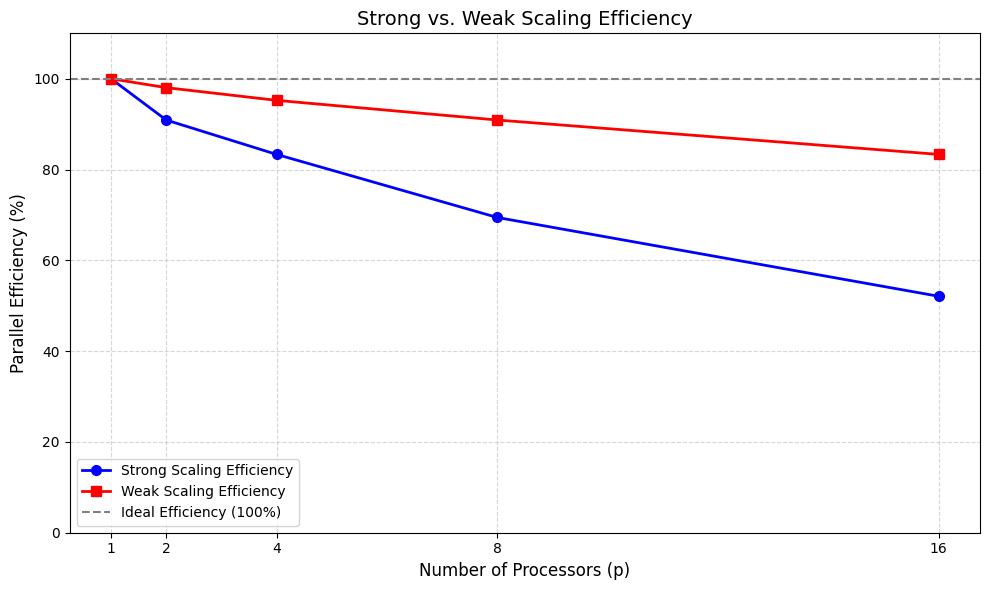

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Assignment 1 - Task 4
# Strong vs. Weak Scaling Efficiency

# Given processor counts
processors = np.array([1, 2, 4, 8, 16])

# Given execution times (seconds)
strong_times = np.array([100, 55, 30, 18, 12])
weak_times = np.array([100, 102, 105, 110, 120])

# Baseline execution times
T1_strong = strong_times[0]
T1_weak = weak_times[0]

# Question 14: Strong-scaling efficiency
# E_strong(p) = T(1) / (p * T(p))
strong_efficiency = (
    T1_strong / (processors * strong_times)
)

# Question 15: Weak-scaling efficiency
# E_weak(p) = T(1) / T(p)
weak_efficiency = T1_weak / weak_times

# Convert efficiencies to percentages
strong_percent = strong_efficiency * 100
weak_percent = weak_efficiency * 100

# Print calculated results
print("TASK 4: STRONG VS. WEAK SCALING")
print("-" * 52)

print(
    f"{'Processors':>10} | "
    f"{'Strong (%)':>12} | "
    f"{'Weak (%)':>10}"
)

print("-" * 52)

for p, es, ew in zip(
    processors, strong_percent, weak_percent
):
    print(f"{p:10d} | {es:12.4f} | {ew:10.4f}")

# Question 16: Plot both efficiencies
plt.figure(figsize=(10, 6))

plt.plot(
    processors,
    strong_percent,
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=7,
    color='blue',
    label="Strong Scaling Efficiency"
)

plt.plot(
    processors,
    weak_percent,
    marker='s',
    linestyle='-',
    linewidth=2,
    markersize=7,
    color='red',
    label="Weak Scaling Efficiency"
)

# Ideal efficiency reference
plt.axhline(
    y=100,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    label="Ideal Efficiency (100%)"
)

# Chart formatting
plt.xlabel("Number of Processors (p)", fontsize=12)
plt.ylabel("Parallel Efficiency (%)", fontsize=12)
plt.title(
    "Strong vs. Weak Scaling Efficiency",
    fontsize=14
)

plt.xticks(processors)
plt.ylim(0, 110)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

# Save the graph
plt.savefig(
    "task4_scaling_efficiency.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [ ]:
from google.colab import files

files.download("task4_scaling_efficiency.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 5 Scaling Analysis and Discussion - Question 21**

Task 5 - Question 21
Speedup and Efficiency with Error Bars

    p      Speedup   Speedup Error    Efficiency (%)   Error (pp)
    1       1.0000          0.0000          100.0000       0.0000
    2       1.9656          0.0069           98.2801       0.3467
    4       3.8144          0.0181           95.3592       0.4523
    8       7.1856          0.0466           89.8204       0.5821
   16      12.7796          0.0953           79.8722       0.5957
   32      19.2308          0.2121           60.0962       0.6627
   64      24.5902          0.3078           38.4221       0.4810
  128      27.7136          0.3901           21.6513       0.3048


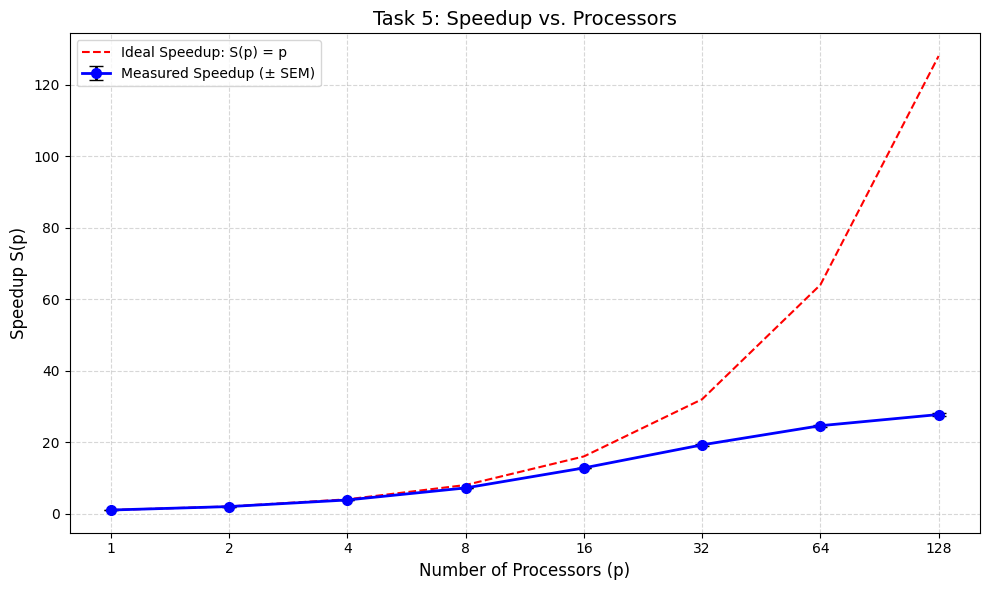

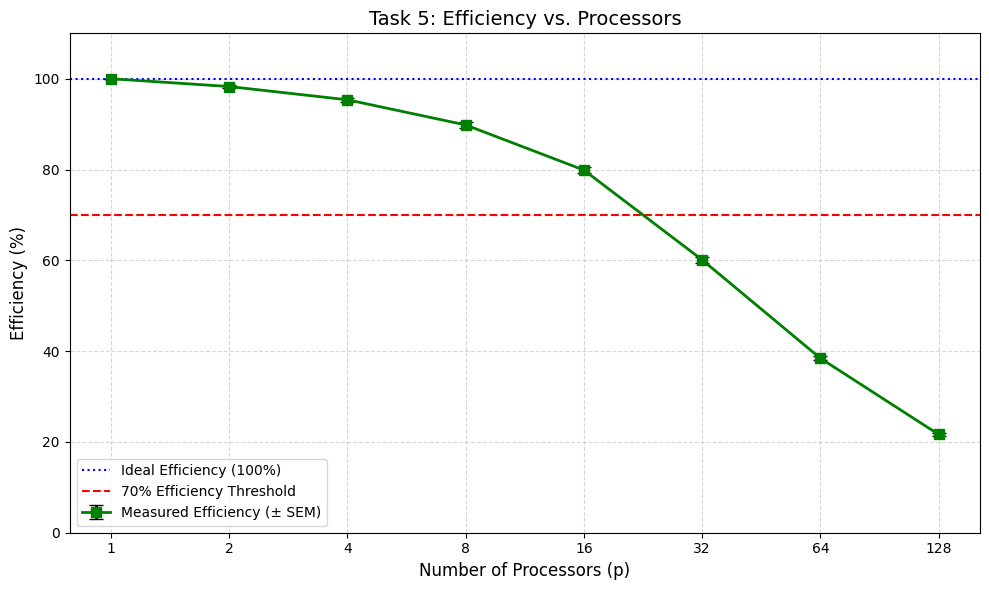

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# Assignment 1 - Task 5 - Question 21
# Plot Speedup and Efficiency with Error Bars
# ==================================================

# Number of processors
p = np.array([1, 2, 4, 8, 16, 32, 64, 128])

# Five execution-time measurements per processor (seconds)
times = np.array([
    [240.0, 238.5, 241.2, 239.8, 240.5],
    [122.5, 121.0, 123.2, 121.8, 122.0],
    [63.0,  62.2,  63.8,  62.5,  63.1],
    [33.5,  32.8,  34.0,  33.1,  33.6],
    [18.9,  18.4,  19.2,  18.6,  18.8],
    [12.5,  12.1,  12.9,  12.3,  12.6],
    [9.8,   9.4,   10.1,  9.6,   9.9],
    [8.7,   8.3,   9.0,   8.5,   8.8]
])

# --------------------------------------------------
# Step 1: Calculate mean, SD, and SEM
# --------------------------------------------------

mean_time = np.mean(times, axis=1)

# Sample standard deviation (n - 1)
std_time = np.std(times, axis=1, ddof=1)

# Standard error of the mean
n = times.shape[1]
sem_time = std_time / np.sqrt(n)

# --------------------------------------------------
# Step 2: Calculate speedup and efficiency
# --------------------------------------------------

# Speedup: S(p) = T(1) / T(p)
speedup = mean_time[0] / mean_time

# Efficiency: E(p) = S(p) / p
efficiency = speedup / p

# --------------------------------------------------
# Step 3: Calculate error bars
# First-order propagation of standard errors
# --------------------------------------------------

relative_error = np.sqrt(
    (sem_time[0] / mean_time[0])**2 +
    (sem_time / mean_time)**2
)

speedup_error = speedup * relative_error
efficiency_error = speedup_error / p

# At p=1, speedup and efficiency equal 1 exactly
# because the same baseline mean is used in both
# numerator and denominator.
speedup_error[0] = 0.0
efficiency_error[0] = 0.0

# Convert efficiency to percentage
efficiency_percent = efficiency * 100
efficiency_error_percent = efficiency_error * 100

# --------------------------------------------------
# Step 4: Print results
# --------------------------------------------------

print("Task 5 - Question 21")
print("Speedup and Efficiency with Error Bars\n")

print(
    f"{'p':>5} "
    f"{'Speedup':>12} "
    f"{'Speedup Error':>15} "
    f"{'Efficiency (%)':>17} "
    f"{'Error (pp)':>12}"
)

for i in range(len(p)):
    print(
        f"{p[i]:5d} "
        f"{speedup[i]:12.4f} "
        f"{speedup_error[i]:15.4f} "
        f"{efficiency_percent[i]:17.4f} "
        f"{efficiency_error_percent[i]:12.4f}"
    )

# ==================================================
# GRAPH 1: SPEEDUP vs. PROCESSORS
# ==================================================

plt.figure(figsize=(10, 6))

plt.errorbar(
    p,
    speedup,
    yerr=speedup_error,
    fmt='o-',
    capsize=5,
    linewidth=2,
    markersize=7,
    color='blue',
    ecolor='black',
    label='Measured Speedup (± SEM)'
)

# Ideal linear speedup
plt.plot(
    p, p,
    '--',
    color='red',
    linewidth=1.5,
    label='Ideal Speedup: S(p) = p'
)

plt.xscale('log', base=2)
plt.xticks(p, [str(x) for x in p])

plt.xlabel('Number of Processors (p)', fontsize=12)
plt.ylabel('Speedup S(p)', fontsize=12)
plt.title('Task 5: Speedup vs. Processors', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig(
    'task5_q21_speedup.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ==================================================
# GRAPH 2: EFFICIENCY vs. PROCESSORS
# ==================================================

plt.figure(figsize=(10, 6))

plt.errorbar(
    p,
    efficiency_percent,
    yerr=efficiency_error_percent,
    fmt='s-',
    capsize=5,
    linewidth=2,
    markersize=7,
    color='green',
    ecolor='black',
    label='Measured Efficiency (± SEM)'
)

# Ideal efficiency
plt.axhline(
    y=100,
    color='blue',
    linestyle=':',
    linewidth=1.5,
    label='Ideal Efficiency (100%)'
)

# 70% efficiency threshold
plt.axhline(
    y=70,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='70% Efficiency Threshold'
)

plt.xscale('log', base=2)
plt.xticks(p, [str(x) for x in p])
plt.ylim(0, 110)

plt.xlabel('Number of Processors (p)', fontsize=12)
plt.ylabel('Efficiency (%)', fontsize=12)
plt.title('Task 5: Efficiency vs. Processors', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig(
    'task5_q21_efficiency.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [2]:
from google.colab import files

files.download("task5_q21_speedup.png")
files.download("task5_q21_efficiency.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Task 5 Scaling Analysis and Discussion - Question 22**

In [3]:

# Task 5 - Question 22
# Identify the first processor count where efficiency < 70%

threshold = 70.0

below_threshold = np.where(efficiency_percent < threshold)[0]

if len(below_threshold) > 0:
    i = below_threshold[0]

    print(f"First processor count below 70%: {p[i]}")
    print(f"Efficiency: {efficiency_percent[i]:.2f}%")
else:
    print("Efficiency does not fall below 70%.")


First processor count below 70%: 32
Efficiency: 60.10%
